In [1]:
import numpy as np
import matplotlib.pyplot as plt
import matplotlib
font = {'size' : 15}
matplotlib.rc('font', **font)
plt.rcParams.update({
    "text.usetex": True,
    "font.family": "Helvetica"
})
from skimage import measure
from skimage.morphology import remove_small_holes
from scipy.ndimage import gaussian_filter, binary_erosion, map_coordinates
from scipy.sparse import coo_matrix
from scipy.sparse.csgraph import dijkstra
import os

In [2]:
source_folder = "interface_data/"
os.makedirs("plots", exist_ok=True)

In [3]:
fields = [0.13, 0.14, 0.15, 0.16]
fields_colors = matplotlib.colormaps.get('tab10')(range(4))

# Is the anisotropy of the material or of the setup?

Material anisotropy: the velocity depends on the **normal** $\alpha$ of the interface, $\log v = \sum_n A_n\cos n\alpha + B_n \sin n\alpha$.
Setup / large scale inhomogeneity (field profile, thickness, illumination): the velocity depends on the **position** only.
For a bubble the two are confounded ($\alpha \simeq \theta$), so NB5 cannot separate them. Two tests that can:

1. **local normal test**: at a fixed position, the small scale tilt $\delta$ of the interface changes $\alpha$ but not the position. Only material anisotropy makes the velocity depend on $\delta$.
2. **radial scaling test** (within one bubble): material anisotropy grows the $n=2$ mode at a constant rate $d c_2/d c_0$; a smooth inhomogeneity (analytic in $x,y$ around the center) gives $d c_2/d c_0 \propto R^2$. Uses only $c_2$ vs $c_0$, so it does not depend on the frame timing.

Each field is a separate experiment: every test is done **within one field**, no axes or statistics are shared between fields.
Both are checked first on synthetic growth (first passage percolation, 16 neighbours) where we know the answer.

### FUNCTIONS

In [4]:
def segment_noevents(data, no_event_val=-1):
    no_event_regions = [ r.astype('int') for r in measure.find_contours(data,no_event_val)]
    no_event_regions_sizes = np.array([r.shape[0] for r in no_event_regions])
    sorted_regions_idx = np.argsort(no_event_regions_sizes)
    inner_region = no_event_regions[sorted_regions_idx[-2]]
    outer_region = no_event_regions[sorted_regions_idx[-1]]
    center = inner_region.mean(axis=0)
    return inner_region,  outer_region, center

In [5]:
def smooth_masked(T, m, s):
    return gaussian_filter(np.where(m, T, 0.), s)/np.maximum(gaussian_filter(m.astype('float'), s), 1e-12)

In [6]:
def local_normal_test(T, m, m_sel, center, ell, L, n_max, stride, n_blocks_th=16, n_flip=500, n_boot=300, seed=0):
    # T = arrival time map, normal alpha = direction of grad T, speed v = 1/|grad T|
    # alpha at scale ell = alpha_L (scale L) + delta,  u = log v_ell - log v_L
    # odd part in delta of sum_n A_n cos n alpha + B_n sin n alpha = sum_n sin(n delta) [-A_n sin n alpha_L + B_n cos n alpha_L]
    # beta = (A_n, B_n) from u (local, position fixed) ;  beta_g = (A_n, B_n) from log v_L vs alpha_L (global, position not fixed)
    # kappa_n = projection of beta on beta_g:  material -> kappa ~ 1, position only -> kappa = 0
    T_l = smooth_masked(T, m, ell)
    T_L = smooth_masked(T, m, L)
    gr_l, gc_l = np.gradient(T_l)
    gr_L, gc_L = np.gradient(T_L)
    ii, jj = np.indices(T.shape)
    r = np.hypot(ii-center[0], jj-center[1])
    th = np.arctan2(ii-center[0], jj-center[1])
    sel = binary_erosion(m_sel, iterations=int(2*L))*m
    keep = np.zeros_like(sel)
    keep[::stride, ::stride] = True
    sel = sel*keep
    delta = np.angle(np.exp(1j*(np.arctan2(gr_l, gc_l) - np.arctan2(gr_L, gc_L))))[sel]
    u = (np.log(np.hypot(gr_L, gc_L)+1e-12) - np.log(np.hypot(gr_l, gc_l)+1e-12))[sel]
    a_L = np.arctan2(gr_L, gc_L)[sel]
    lv_L = -np.log(np.hypot(gr_L, gc_L)+1e-12)[sel]
    r_s, th_s = r[sel], th[sel]
    ok = (np.abs(delta) < np.pi/2)*np.isfinite(u)
    lo, hi = np.percentile(u[ok], [1, 99])
    ok = ok*(u > lo)*(u < hi)
    delta, u, a_L, lv_L, r_s, th_s = delta[ok], u[ok], a_L[ok], lv_L[ok], r_s[ok], th_s[ok]
    X_odd = np.array([ f for n in range(1, n_max+1) for f in (-np.sin(n*a_L)*np.sin(n*delta), np.cos(n*a_L)*np.sin(n*delta))]).T
    X_even = np.array([np.ones_like(u), delta**2]).T
    X_g = np.array([ f for n in range(1, n_max+1) for f in (np.cos(n*a_L), np.sin(n*a_L))]).T
    r_bin = np.digitize(r_s, np.linspace(r_s.min(), r_s.max()+1, 21))
    D = (r_bin[:, None] == np.unique(r_bin)[None, :]).astype('float')   # v_L also depends on r (time), remove it
    # blocks: n_blocks_th sectors x annuli of 4L, used for the null and the errors
    blk = np.floor((th_s+np.pi)/(2*np.pi)*n_blocks_th).astype('int')*1000 + (r_s//(4*L)).astype('int')
    blk = np.unique(blk, return_inverse=True)[1]
    n_blk = blk.max()+1
    def fit(w=None, s=None):
        if(w is None):
            w = np.ones_like(u)
        if(s is None):
            s = np.ones_like(u)
        sw = np.sqrt(w)[:, None]
        X = np.hstack([X_odd*s[:, None], X_even, (np.sin(delta)*s)[:, None]])
        beta = np.linalg.lstsq(X*sw, u*sw[:,0], rcond=None)[0][:2*n_max]
        beta_g = np.linalg.lstsq(np.hstack([X_g, D])*sw, lv_L*sw[:,0], rcond=None)[0][:2*n_max]
        return beta, beta_g
    def kappa(beta, beta_g):
        return np.array([ np.dot(beta[2*n:2*n+2], beta_g[2*n:2*n+2])/np.dot(beta_g[2*n:2*n+2], beta_g[2*n:2*n+2]) for n in range(n_max)])
    beta, beta_g = fit()
    k_obs = kappa(beta, beta_g)
    rng = np.random.default_rng(seed)
    # null: mirror symmetry about the local normal -> flip the sign of delta in random blocks
    k_null = np.array([ kappa(fit(s=rng.choice([-1., 1.], n_blk)[blk])[0], beta_g) for f in range(n_flip)])
    p = (np.abs(k_null) >= np.abs(k_obs)[None, :]).mean(axis=0)
    # errors: block bootstrap
    k_boot = np.array([ kappa(*fit(w=np.bincount(rng.integers(0, n_blk, n_blk), minlength=n_blk)[blk].astype('float'))) for b in range(n_boot)])
    return k_obs, k_boot.std(axis=0), p, beta, beta_g, delta.std()

In [7]:
def fpp(N, eps_mat, eps_pos, eps_spot, phi, sigma, corr, seed, n_mode=2, r0=400.):
    # synthetic growth from the center: first passage percolation on a 16-neighbour lattice
    # slowness s = exp(sigma*eta) with eta gaussian of correlation length corr (disorder)
    # eps_mat  : material, speed of a bond depends on its direction  exp(eps_mat cos n(beta - phi))
    # eps_pos  : position only, speed depends on the polar angle of the position  exp(eps_pos cos n(theta - phi))
    # eps_spot : position only, smooth (analytic) profile  exp(eps_spot (r/r0)^2 cos 2(theta - phi))
    rng = np.random.default_rng(seed)
    eta = gaussian_filter(rng.normal(size=(N, N)), corr)
    eta /= eta.std()
    ii, jj = np.indices((N, N))
    c = (N-1)/2
    th = np.arctan2(ii-c, jj-c)
    r2 = (ii-c)**2 + (jj-c)**2
    s = np.exp(sigma*eta - eps_pos*np.cos(n_mode*(th-phi)) - eps_spot*r2/r0**2*np.cos(2*(th-phi)))
    offs = [(0,1),(1,0),(1,1),(1,-1),(1,2),(2,1),(2,-1),(1,-2)]
    offs = offs + [(-a,-b) for a,b in offs]
    idx = np.arange(N*N).reshape(N, N)
    rows, cols, w = [], [], []
    for a, b in offs:
        i0 = slice(max(0,-a), N-max(0,a))
        i1 = slice(max(0,a), N-max(0,-a))
        j0 = slice(max(0,-b), N-max(0,b))
        j1 = slice(max(0,b), N-max(0,-b))
        beta = np.arctan2(a, b)
        cost = np.hypot(a, b)*0.5*(s[i0, j0]+s[i1, j1])/np.exp(eps_mat*np.cos(n_mode*(beta-phi)))
        rows.append(idx[i0, j0].ravel())
        cols.append(idx[i1, j1].ravel())
        w.append(cost.ravel())
    G = coo_matrix((np.concatenate(w), (np.concatenate(rows), np.concatenate(cols))), shape=(N*N, N*N)).tocsr()
    T = dijkstra(G, indices=idx[int(c), int(c)])
    return T.reshape(N, N)

In [8]:
def modes(R, th, n_max):
    # c_n(t) = < R(theta,t) exp(-i n theta) >_theta, as fourier_modes in NB5
    return np.array([ (R*np.exp(-1j*n*th)[None,:]).mean(axis=1) for n in range(0, n_max+1)]).T

def window_eps(c, n, n_win, c0_min, c0_max):
    # eps_n = d c_n / d c_0 (least squares slope) in n_win windows of c_0
    c0 = c[:, 0].real
    edges = np.linspace(c0_min, c0_max, n_win+1)
    R_w, e_w = [], []
    for a, b in zip(edges[:-1], edges[1:]):
        w = (c0 >= a)*(c0 < b)
        x = c0[w]-c0[w].mean()
        y = c[w, n]-c[w, n].mean()
        R_w.append(c0[w].mean())
        e_w.append((x*y).sum()/(x*x).sum())
    return np.array(R_w), np.array(e_w)

def coherent(e_w, n, phi):
    # relative velocity modulation 2 eps_n along the axis phi [R ~ cos n(theta-phi)] and orthogonal to it
    z = 2*e_w*np.exp(1j*n*phi)
    return z.real, z.imag

def interface_from_T(T, center, n_th, r_max, t_list, dr=0.5):
    # R(theta,t) from an arrival time map, along rays (only for the synthetic growth)
    th = np.linspace(-np.pi, np.pi, n_th, endpoint=False)
    r = np.arange(0, r_max, dr)
    Tr = map_coordinates(T, [center[0] + r[None,:]*np.sin(th)[:,None], center[1] + r[None,:]*np.cos(th)[:,None]], order=1)
    Tr = np.maximum.accumulate(Tr, axis=1)
    R = np.array([ (Tr <= t).sum(axis=1)*dr for t in t_list])
    return R, th

### Test 1: local normal vs position
Synthetic calibration: `iso` (no anisotropy), `material`, `position` (same elliptic shape as `material` but from the position), `spot` (smooth profile). $\varepsilon = 0.08$, 8 seeds each.

In [9]:
N_syn = 600
phi_syn = np.radians(-70)
ell, L = 4, 25
syn_cases = {'iso': (0, 0, 0), 'material': (0.08, 0, 0), 'position': (0, 0.08, 0), 'spot': (0, 0, 0.08)}
c_syn = (N_syn-1)/2
ii, jj = np.indices((N_syn, N_syn))
m_syn = np.hypot(ii-c_syn, jj-c_syn) < 0.45*N_syn
kappa_syn = {}
for name, (e_m, e_p, e_s) in syn_cases.items():
    kappa_syn[name] = []
    for seed in range(8):
        T = fpp(N_syn, e_m, e_p, e_s, phi_syn, 0.5, 2., seed=100+seed, r0=270.)
        k_obs, k_err, p, beta, beta_g, d_std = local_normal_test(T, m_syn, m_syn, (c_syn, c_syn), ell, L, 2, 3, n_flip=200, n_boot=100, seed=seed)
        kappa_syn[name].append((k_obs[1], k_err[1], p[1]))
    kappa_syn[name] = np.array(kappa_syn[name])
    print("%-9s kappa_2 = %.2f +- %.2f (sd over seeds)   p < 0.05 in %i/8   delta std %.2f" % (name, kappa_syn[name][:,0].mean(), kappa_syn[name][:,0].std(), (kappa_syn[name][:,2] < 0.05).sum(), d_std))

iso       kappa_2 = 0.28 +- 1.00 (sd over seeds)   p < 0.05 in 0/8   delta std 0.44


material  kappa_2 = 0.65 +- 0.29 (sd over seeds)   p < 0.05 in 7/8   delta std 0.44


position  kappa_2 = -0.01 +- 0.16 (sd over seeds)   p < 0.05 in 0/8   delta std 0.44


spot      kappa_2 = -0.10 +- 0.59 (sd over seeds)   p < 0.05 in 0/8   delta std 0.44


In [10]:
# real data: T = switching frame, never switched pixels excluded
kappa_real = {}
ell_real, L_real = 5, 40
for field in fields:
    data = np.loadtxt("data/file_field%1.2f.csv" % field, delimiter=',').astype('int')
    inner_region, outer_region, center = segment_noevents(data)
    m = data > -1
    m_sel = remove_small_holes(m, 1000)   # isolated never switched pixels inside the bubble
    k_obs, k_err, p, beta, beta_g, d_std = local_normal_test(data.astype('float'), m, m_sel, center, ell_real, L_real, 2, 3, n_flip=500, n_boot=300, seed=1)
    kappa_real[field] = (k_obs[1], k_err[1], p[1], np.hypot(*beta_g[2:4]), d_std)
    print("%1.2f  kappa_2 = %.2f +- %.2f  p = %.2f   global n=2 amplitude of log v %.3f   delta std %.3f" % ((field,) + kappa_real[field]))


0.13  kappa_2 = -2.70 +- 4.00  p = 0.26   global n=2 amplitude of log v 0.037   delta std 0.061


0.14  kappa_2 = 1.46 +- 9.73  p = 0.79   global n=2 amplitude of log v 0.018   delta std 0.058


0.15  kappa_2 = 1.98 +- 3.40  p = 0.44   global n=2 amplitude of log v 0.034   delta std 0.054


0.16  kappa_2 = -1.92 +- 1.73  p = 0.18   global n=2 amplitude of log v 0.055   delta std 0.053


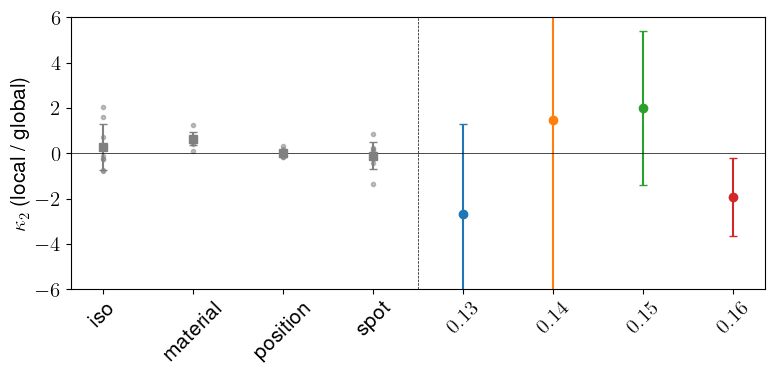

In [11]:
fig, ax = plt.subplots(figsize=(8,4))
for i, name in enumerate(syn_cases):
    ax.errorbar(i, kappa_syn[name][:,0].mean(), yerr=kappa_syn[name][:,0].std(), marker='s', color='grey', capsize=3)
    ax.plot(i + np.zeros(8), kappa_syn[name][:,0], '.', color='grey', alpha=0.5)
for j, (color, field) in enumerate(zip(fields_colors, fields)):
    ax.errorbar(len(syn_cases)+j, kappa_real[field][0], yerr=kappa_real[field][1], marker='o', color=color, capsize=3)
ax.set_xticks(range(len(syn_cases)+len(fields)))
ax.set_xticklabels(list(syn_cases) + ["$%1.2f$" % f for f in fields], rotation=45)
ax.axhline(0, color='black', lw=0.5)
ax.axvline(len(syn_cases)-0.5, color='black', ls='dashed', lw=0.5)
ax.set_ylabel("$\\kappa_2$ (local / global)")
ax.set_ylim(-6, 6)
plt.tight_layout()
plt.savefig("plots/anisotropy_test_local_normal.pdf", bbox_inches='tight')
plt.show()

### Test 2: coherent $n$-mode growth inside one bubble, and its scaling with $R$
$2\varepsilon_n = 2\, d c_n/d c_0$ is the relative velocity modulation of the growth in a window of $R$.
Each window is projected on the axis of the **other windows of the same field** (leave one out, no circularity), $2\varepsilon_n^{\parallel}$.
Null (isotropic, independent windows): each window keeps $|\varepsilon_n|$ with a random phase. If the low modes relax back (negative lag-1 correlation between windows) this null is conservative.
Material $\to 2\varepsilon_2^{\parallel}$ constant in $R$, smooth inhomogeneity $\to \propto R^2$, isotropic $\to$ 0. Modes $n=1,3,4$ as controls.

In [12]:
def loo_parallel(e_w):
    # 2 eps of each window along the axis of the other windows (leave one out)
    a_par = []
    for k in range(len(e_w)):
        S = np.delete(e_w, k).sum()
        a_par.append(2*np.real(e_w[k]*np.conj(S)/np.abs(S)))
    return np.array(a_par)

def loo_test(e_w, n_rand=5000, seed=0):
    rng = np.random.default_rng(seed)
    obs = loo_parallel(e_w).mean()
    null = np.array([ loo_parallel(np.abs(e_w)*np.exp(1j*rng.uniform(0, 2*np.pi, len(e_w)))).mean() for i in range(n_rand)])
    return obs, (null >= obs).mean()

def lag1(e_w):
    d = e_w - e_w.mean()
    return np.real((d[:-1]*np.conj(d[1:])).sum())/(np.abs(d)**2).sum()

In [13]:
# synthetic: one bubble at a time, same windows as the data
N_syn2 = 900
c_syn2 = (N_syn2-1)/2
n_win = 8
syn2_cases = {'material': (0.08, 0, 0), 'spot': (0, 0, 0.10), 'iso': (0, 0, 0)}
syn2 = {}
for name, (e_m, e_p, e_s) in syn2_cases.items():
    syn2[name] = []
    for seed in range(4):
        T = fpp(N_syn2, e_m, e_p, e_s, phi_syn, 0.5, 2., seed=seed, r0=400.)
        ii, jj = np.indices(T.shape)
        t_list = np.quantile(T[np.hypot(ii-c_syn2, jj-c_syn2) < 430], np.linspace(0.01, 0.9, 400))
        R, th = interface_from_T(T, (c_syn2, c_syn2), 1024, 440, t_list)
        R_w, e_w = window_eps(modes(R, th, 2), 2, n_win, 100, 400)
        obs, p = loo_test(e_w, seed=seed)
        syn2[name].append((R_w, loo_parallel(e_w), obs, p))
    print("%-9s 2 eps_par = %s   p = %s" % (name, ' '.join('%.3f' % s[2] for s in syn2[name]), ' '.join('%.3f' % s[3] for s in syn2[name])))

material  2 eps_par = 0.064 0.032 0.028 0.031   p = 0.000 0.029 0.031 0.024


spot      2 eps_par = 0.060 0.039 0.033 0.026   p = 0.000 0.025 0.028 0.067


iso       2 eps_par = 0.014 0.004 -0.017 0.008   p = 0.105 0.471 0.826 0.340


In [14]:
real2 = {}
for field in fields:
    d = np.load("%sinterface_field=%1.2f.npz" % (source_folder,field))
    c = modes(d['interface'][:, :-1], d['theta_new'][:-1], 4)
    real2[field] = {}
    for n in range(1, 5):
        R_w, e_w = window_eps(c, n, n_win, 1.3*c[0,0].real, c[-1,0].real)   # start away from the initial domain
        obs, p = loo_test(e_w, seed=n)
        real2[field][n] = (R_w, e_w, loo_parallel(e_w), obs, p)
        print("%1.2f  n=%i  2 eps_par = %6.3f  p = %.3f   axis %4i deg   lag-1 corr %5.2f" % (field, n, obs, p, round(np.degrees(-np.angle(e_w.sum())/n)), lag1(e_w)))

0.13  n=1  2 eps_par =  0.006  p = 0.552   axis   56 deg   lag-1 corr  0.16
0.13  n=2  2 eps_par =  0.043  p = 0.224   axis  -70 deg   lag-1 corr -0.49


0.13  n=3  2 eps_par = -0.073  p = 0.927   axis   33 deg   lag-1 corr -0.25
0.13  n=4  2 eps_par =  0.012  p = 0.412   axis  -43 deg   lag-1 corr -0.31


0.14  n=1  2 eps_par = -0.082  p = 0.894   axis  116 deg   lag-1 corr -0.29
0.14  n=2  2 eps_par =  0.029  p = 0.251   axis  -71 deg   lag-1 corr -0.04


0.14  n=3  2 eps_par =  0.001  p = 0.573   axis   21 deg   lag-1 corr -0.13
0.14  n=4  2 eps_par = -0.012  p = 0.721   axis   -6 deg   lag-1 corr -0.27


0.15  n=1  2 eps_par =  0.045  p = 0.090   axis  -60 deg   lag-1 corr  0.07
0.15  n=2  2 eps_par =  0.013  p = 0.446   axis  -77 deg   lag-1 corr -0.17


0.15  n=3  2 eps_par = -0.058  p = 0.964   axis   31 deg   lag-1 corr -0.42
0.15  n=4  2 eps_par =  0.014  p = 0.321   axis  -17 deg   lag-1 corr  0.21


0.16  n=1  2 eps_par =  0.021  p = 0.345   axis  118 deg   lag-1 corr -0.04
0.16  n=2  2 eps_par =  0.045  p = 0.011   axis  -83 deg   lag-1 corr  0.01


0.16  n=3  2 eps_par = -0.004  p = 0.645   axis   40 deg   lag-1 corr -0.59
0.16  n=4  2 eps_par =  0.005  p = 0.470   axis   34 deg   lag-1 corr  0.10


In [15]:
# scaling with R inside each field: 2 eps_par ~ R^gamma, error of each window from the orthogonal component
gammas = np.linspace(-4, 6, 201)
gamma_fit = {}
for field in fields:
    R_w, e_w, a_par, obs, p = real2[field][2]
    a_perp = np.array([ 2*np.imag(e_w[k]*np.conj(np.delete(e_w, k).sum())/np.abs(np.delete(e_w, k).sum())) for k in range(len(e_w))])
    sig = np.sqrt(np.mean(a_perp**2))
    chi2 = []
    for g in gammas:
        x = (R_w/R_w.mean())**g
        A = (a_par*x).sum()/(x*x).sum()
        chi2.append((((a_par-A*x)/sig)**2).sum())
    chi2 = np.array(chi2)
    ci = gammas[chi2 <= chi2.min()+1]
    gamma_fit[field] = (chi2, sig)
    print("%1.2f  gamma = %.1f  1 sigma [%.1f, %.1f]   Delta chi2(gamma=0) = %.1f   Delta chi2(gamma=2) = %.1f" % (field, gammas[np.argmin(chi2)], ci.min(), ci.max(), chi2[np.argmin(np.abs(gammas))]-chi2.min(), chi2[np.argmin(np.abs(gammas-2))]-chi2.min()))

0.13  gamma = -4.0  1 sigma [-4.0, -0.9]   Delta chi2(gamma=0) = 1.4   Delta chi2(gamma=2) = 2.1
0.14  gamma = 6.0  1 sigma [3.7, 6.0]   Delta chi2(gamma=0) = 4.9   Delta chi2(gamma=2) = 2.4
0.15  gamma = -4.0  1 sigma [-4.0, 6.0]   Delta chi2(gamma=0) = 0.5   Delta chi2(gamma=2) = 0.5
0.16  gamma = 0.2  1 sigma [-0.5, 1.2]   Delta chi2(gamma=0) = 0.1   Delta chi2(gamma=2) = 2.0


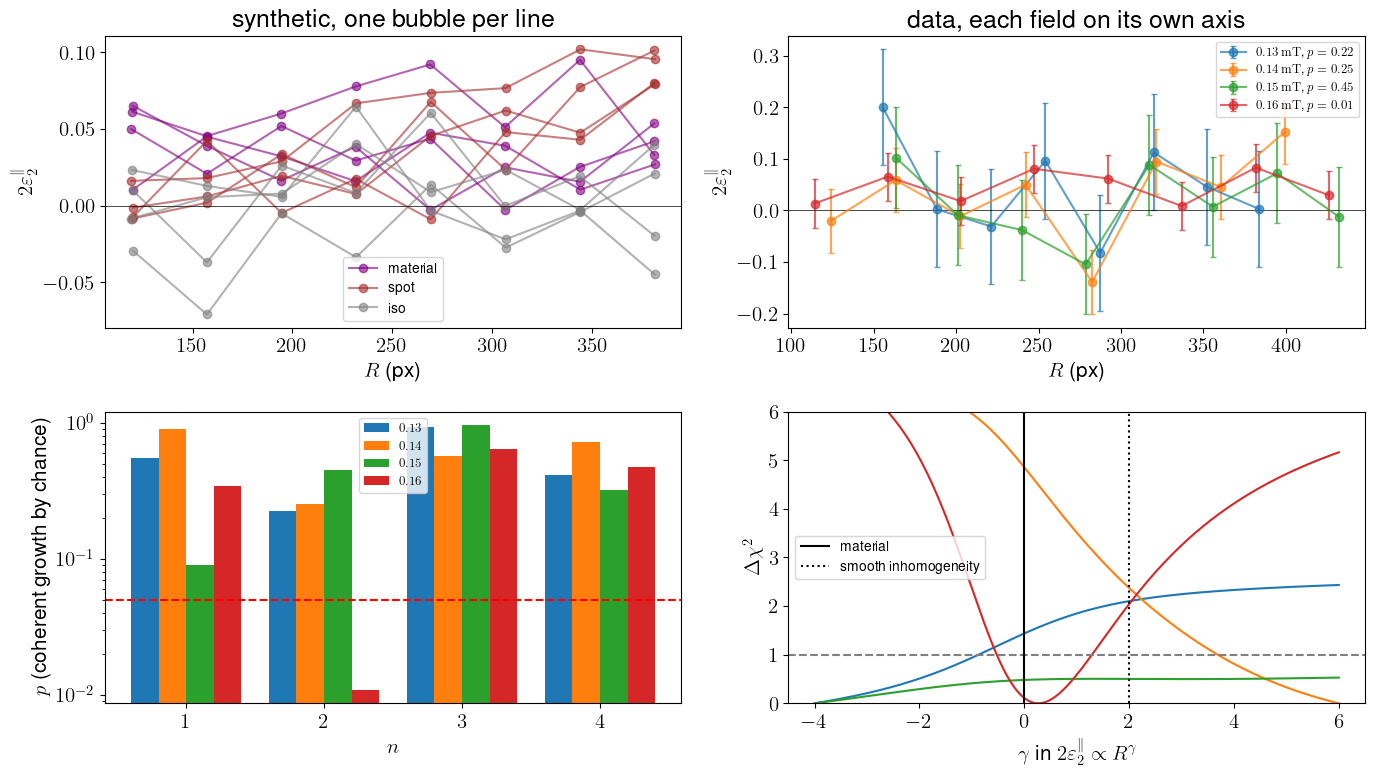

In [16]:
fig, ax = plt.subplots(figsize=(14,8), ncols=2, nrows=2)
ax = ax.flatten()
for name, color in zip(syn2_cases, ['purple', 'brown', 'grey']):
    for s in syn2[name]:
        ax[0].plot(s[0], s[1], marker='o', color=color, alpha=0.6, label=name if s is syn2[name][0] else None)
ax[0].axhline(0, color='black', lw=0.5)
ax[0].set_title("synthetic, one bubble per line")
ax[0].set_xlabel("$R$ (px)")
ax[0].set_ylabel("$2\\varepsilon_2^{\\parallel}$")
ax[0].legend(fontsize=10)
for color, field in zip(fields_colors, fields):
    R_w, e_w, a_par, obs, p = real2[field][2]
    ax[1].errorbar(R_w, a_par, yerr=gamma_fit[field][1], marker='o', color=color, capsize=2, alpha=0.7, label="$%1.2f \\, \\rm{mT}$, $p=%.2f$" % (field, p))
ax[1].axhline(0, color='black', lw=0.5)
ax[1].set_title("data, each field on its own axis")
ax[1].set_xlabel("$R$ (px)")
ax[1].set_ylabel("$2\\varepsilon_2^{\\parallel}$")
ax[1].legend(fontsize=9)
for j, (color, field) in enumerate(zip(fields_colors, fields)):
    ax[2].bar(np.arange(1, 5) + 0.2*(j-1.5), [real2[field][n][4] for n in range(1, 5)], width=0.2, color=color, label="$%1.2f$" % field)
ax[2].axhline(0.05, color='red', ls='dashed')
ax[2].set_yscale('log')
ax[2].set_xticks(range(1, 5))
ax[2].set_xlabel("$n$")
ax[2].set_ylabel("$p$ (coherent growth by chance)")
ax[2].legend(fontsize=9)
for color, field in zip(fields_colors, fields):
    chi2, sig = gamma_fit[field]
    ax[3].plot(gammas, chi2-chi2.min(), color=color)
ax[3].axhline(1, color='grey', ls='dashed')
ax[3].axvline(0, color='black', label="material")
ax[3].axvline(2, color='black', ls='dotted', label="smooth inhomogeneity")
ax[3].set_ylim(0, 6)
ax[3].set_xlabel("$\\gamma$ in $2\\varepsilon_2^{\\parallel} \\propto R^\\gamma$")
ax[3].set_ylabel("$\\Delta\\chi^2$")
ax[3].legend(fontsize=10)
plt.tight_layout()
plt.savefig("plots/anisotropy_test_radial_scaling.pdf", bbox_inches='tight')
plt.show()